In [2]:
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv

from langchain_groq import ChatGroq
from langchain_core.messages.utils import trim_messages,count_tokens_approximately

In [3]:
load_dotenv()

True

In [4]:
model = ChatGroq(model="openai/gpt-oss-120b")

In [5]:
MAX_TOKENS = 150

In [6]:
def call_model(state: MessagesState):
    
    # Trim conversation history -> last N messages that fit within the token budget
    messages = trim_messages(
        state["messages"],
        strategy="last",                      
        token_counter=count_tokens_approximately,
        max_tokens=MAX_TOKENS
    )

    print('Current Token Count ->', count_tokens_approximately(messages=messages))

    for message in messages:
        print(message.content)

    response = model.invoke(messages)

    return {"messages": [response]}

In [7]:
builder = StateGraph(MessagesState)
builder.add_node("call_model", call_model)
builder.add_edge(START, "call_model")

In [8]:
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

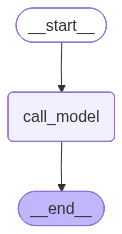

In [10]:
graph

In [9]:
config = {"configurable": {"thread_id": "chat-1"}}

result = graph.invoke(
    {"messages": [{"role": "user", "content": "Hi, my name is Kuldip."}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 10
Hi, my name is Kuldip.


'Hello Kuldip! 👋 Nice to meet you. How can I assist you today?'

In [10]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "I am learning LangGraph."}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 41
Hi, my name is Kuldip.
Hello Kuldip! 👋 Nice to meet you. How can I assist you today?
I am learning LangGraph.


'That’s great! LangGraph is a powerful framework for building composable, multi‑step LLM applications, and there’s a lot you can do with it. Here’s a quick roadmap to get you up to speed, plus some hands‑on examples you can try right away.\n\n---\n\n## 1️⃣ Core Concepts at a Glance\n\n| Concept | What It Is | Why It Matters |\n|---------|------------|----------------|\n| **Node (or “Agent”)** | A single LLM call (or any function) that takes inputs and produces outputs. | Encapsulates a piece of logic you can reuse. |\n| **Edge** | The connection that passes data from one node’s output to another node’s input. | Defines the workflow and data flow. |\n| **Graph** | A collection of nodes + edges that together implement a multi‑step reasoning pipeline. | Lets you orchestrate complex tasks (e.g., retrieval → reasoning → summarization). |\n| **State** | The mutable context that travels through the graph (often a dict). | Enables memory, branching, and conditional logic. |\n| **Loop / Conditi

In [11]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "Can you explain short term memory?"}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 13
Can you explain short term memory?


'**Short‑term memory (STM)** is the brain’s temporary storage system for information that we need to keep “online” for a few seconds to a few minutes. It lets us hold a phone number long enough to dial it, follow a sentence while reading, or keep a mental image while we manipulate it.\n\nBelow is a compact overview of the key features, classic models, neural underpinnings, and everyday examples.\n\n---\n\n## 1. Core Characteristics\n\n| Feature | Typical Value | What it means |\n|---------|----------------|---------------|\n| **Capacity** | 5–9 “chunks” of information (Miller, 1956) | A *chunk* can be a single digit, a word, or a meaningful group (e.g., “FBI” counts as one chunk). |\n| **Duration** | ~15–30\u202fseconds without rehearsal (Peterson & Peterson, 1959) | If you don’t actively rehearse the material, it fades quickly. |\n| **Encoding** | Primarily **acoustic/phonological** (for verbal material) and **visual‑spatial** (for images) | You tend to “talk to yourself” or “see a pi

In [12]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "What is my name?"}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 8
What is my name?


'I don’t actually know your name—could you let me know what you’d like me to call you?'

In [13]:
for item in graph.get_state({"configurable": {"thread_id": "chat-1"}}).values['messages']:
    print(item.content)
    print('-'*120)

Hi, my name is Kuldip.
------------------------------------------------------------------------------------------------------------------------
Hello Kuldip! 👋 Nice to meet you. How can I assist you today?
------------------------------------------------------------------------------------------------------------------------
I am learning LangGraph.
------------------------------------------------------------------------------------------------------------------------
That’s great! LangGraph is a powerful framework for building composable, multi‑step LLM applications, and there’s a lot you can do with it. Here’s a quick roadmap to get you up to speed, plus some hands‑on examples you can try right away.

---

## 1️⃣ Core Concepts at a Glance

| Concept | What It Is | Why It Matters |
|---------|------------|----------------|
| **Node (or “Agent”)** | A single LLM call (or any function) that takes inputs and produces outputs. | Encapsulates a piece of logic you can reuse. |
| **Edge** | 